# Sales data cleaning and analysis

Cleaning a messy sales file and checking revenue by month, product and city. The data is synthetic (made with make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
blue = "#2b6cb0"

## Loading the data

In [2]:
raw = pd.read_csv("sales_raw_messy.csv")
print(len(raw))
raw.head(10)

630


,order_id,order_date,city,product,quantity,unit_price,customer_rating
0,1001,2025-02-02,Faisalabad,Monitor,1.0,263.45,3.0
1,1002,2025-10-10,Islamabad,Monitor,NaN,262.65,4.0
2,1003,2025-08-27,Faisalabad,Monitor,3.0,NaN,1.0
3,1004,2025-06-10,Multan,Laptop,2.0,885.79,4.0
4,1005,2025-06-08,MULTAN,Keyboard,1.0,40.74,5.0
5,1006,2025-11-10,Faisalabad,Headphones,1.0,99999.00,1.0
6,1007,2025-02-01,Islamabad,Phone,1.0,530.56,2.0
7,1008,2025-09-12,multan,Headphones,3.0,89.75,4.0
8,1009,15/03/2025,Karachi,Keyboard,1.0,42.84,4.0
9,1010,2025-02-04,Faisalabad,Keyboard,5.0,44.27,NaN


## Checking what is wrong

In [3]:
raw.isna().sum()

order_id            0
order_date          0
city                0
product             0
quantity           15
unit_price         26
customer_rating    41
dtype: int64

In [4]:
print(raw.duplicated().sum())
print(raw["city"].nunique())
raw["city"].unique()

30
15


<StringArray>
[   'Faisalabad',     'Islamabad',        'Multan',     '  MULTAN ',
        'multan',       'Karachi',        'Lahore',     'islamabad',
    'faisalabad',     '  LAHORE ', '  FAISALABAD ',        'lahore',
    '  KARACHI ',  '  ISLAMABAD ',       'karachi']
Length: 15, dtype: str

In [5]:
raw["unit_price"].describe()

count      604.000000
mean       651.002252
std       5428.399327
min        -50.000000
25%         84.995000
50%        252.250000
75%        530.707500
max      99999.000000
Name: unit_price, dtype: float64

## Cleaning

In [6]:
df = raw.copy()

before = len(df)
df = df.drop_duplicates()
print(before - len(df), "duplicates removed")

30 duplicates removed


In [7]:
d1 = pd.to_datetime(df["order_date"], format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(df["order_date"], format="%d/%m/%Y", errors="coerce")
df["order_date"] = d1.fillna(d2)
df["order_date"].isna().sum()

np.int64(0)

In [8]:
df["city"] = df["city"].str.strip().str.title()
df["city"].value_counts()

city
Islamabad     122
Karachi       122
Faisalabad    121
Lahore        120
Multan        115
Name: count, dtype: int64

In [9]:
wrong = (df["unit_price"] <= 0) | (df["unit_price"] > 5000)
print(wrong.sum(), "wrong prices")
df.loc[wrong, "unit_price"] = np.nan

3 wrong prices


In [10]:
med_price = df.groupby("product")["unit_price"].transform("median")
df["unit_price"] = df["unit_price"].fillna(med_price)
df["quantity"] = df["quantity"].fillna(df["quantity"].median()).astype(int)
df.isna().sum()

order_id            0
order_date          0
city                0
product             0
quantity            0
unit_price          0
customer_rating    40
dtype: int64

In [11]:
df["revenue"] = (df["quantity"] * df["unit_price"]).round(2)
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df = df.sort_values("order_date").reset_index(drop=True)
df.to_csv("sales_clean.csv", index=False)
print(len(df))
df.head()

600


,order_id,order_date,city,product,quantity,unit_price,customer_rating,revenue,month
0,1381,2025-01-02,Karachi,Headphones,4,97.02,3.0,388.08,2025-01
1,1104,2025-01-03,Faisalabad,Laptop,3,808.76,5.0,2426.28,2025-01
2,1575,2025-01-03,Multan,Laptop,4,873.54,3.0,3494.16,2025-01
3,1465,2025-01-03,Islamabad,Monitor,1,281.70,4.0,281.70,2025-01
4,1303,2025-01-04,Karachi,Phone,1,506.57,3.0,506.57,2025-01


## Analysis

In [12]:
monthly = df.groupby("month")["revenue"].sum()
by_product = df.groupby("product")["revenue"].sum().sort_values()
by_city = df.groupby("city")["revenue"].sum().sort_values(ascending=False)
rating = df.groupby("product")["customer_rating"].mean().sort_values()

print("total revenue: ${:,.0f}".format(df["revenue"].sum()))
print("average order: ${:,.0f}".format(df["revenue"].mean()))
print("best month:", monthly.idxmax())
print("top product:", by_product.idxmax())
print("top city:", by_city.idxmax())

total revenue: $621,130
average order: $1,035
best month: 2025-10
top product: Laptop
top city: Lahore


## Charts

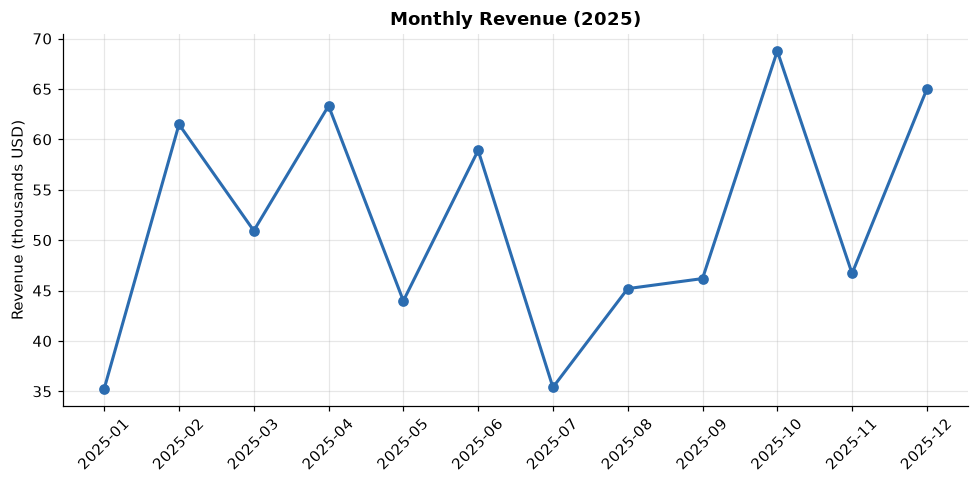

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(monthly.index, monthly.values / 1000, marker="o", color=blue, linewidth=2)
ax.set_title("Monthly Revenue (2025)", fontweight="bold")
ax.set_ylabel("Revenue (thousands USD)")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("chart1_monthly_revenue.png")
plt.show()

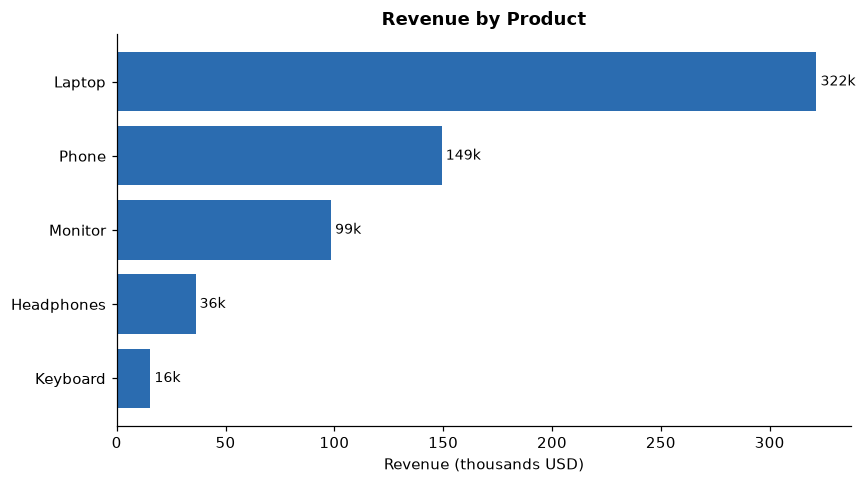

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(by_product.index, by_product.values / 1000, color=blue)
ax.set_title("Revenue by Product", fontweight="bold")
ax.set_xlabel("Revenue (thousands USD)")
for i, v in enumerate(by_product.values / 1000):
    ax.text(v, i, f" {v:,.0f}k", va="center", fontsize=9)
fig.tight_layout()
fig.savefig("chart2_revenue_by_product.png")
plt.show()

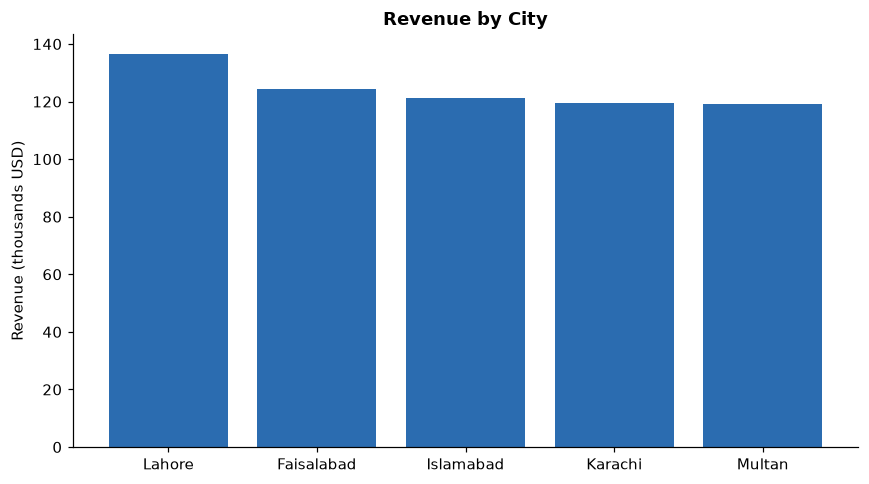

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(by_city.index, by_city.values / 1000, color=blue)
ax.set_title("Revenue by City", fontweight="bold")
ax.set_ylabel("Revenue (thousands USD)")
fig.tight_layout()
fig.savefig("chart3_revenue_by_city.png")
plt.show()

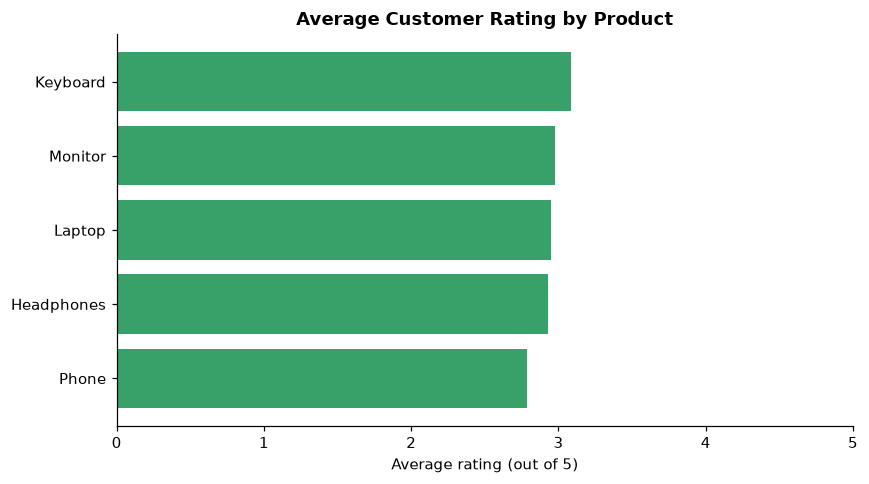

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(rating.index, rating.values, color="#38a169")
ax.set_xlim(0, 5)
ax.set_title("Average Customer Rating by Product", fontweight="bold")
ax.set_xlabel("Average rating (out of 5)")
fig.tight_layout()
fig.savefig("chart4_avg_rating.png")
plt.show()

## Summary

- 630 raw rows became 600 clean orders
- total revenue is about $621K, average order about $1,035
- October was the best month
- laptops make the most revenue and Lahore is the top city
- ratings are about the same for all products